# Topical Lectures, Controls
## Real drone, part 2: what the drone measures (motors off)

Andreas Freise, 28.10.2026

### Goal

There are two ways to fly the Crazyflie. The firmware contains a complete set of controllers, and with the flow deck the drone holds its position on its own; a flight is then a sequence of position setpoints sent from the laptop or from cfclient. Or we send velocity commands instead of positions: the position loop then runs in our own Python code on the laptop, which receives the measurements and sends the commands by radio, while the firmware keeps the inner loops. We use the second way, to learn how to tune a controller on a real system. In principle this can be done for each loop in turn; we do it for the outermost one, the position loop in `x` and `y`, and leave the velocity loop, the attitude loop and the height to the firmware.

To design that loop we first need to know the system we are closing it around. That has two sides. The measurement side, what the drone reports as its position and velocity, in which directions and how reliably, can be measured with the motors off, and that is this notebook. The actuator side, how fast the drone follows a velocity command, needs a flight under the firmware's own controllers and is the first thing part 3 does.

In this notebook we move the drone by hand through a short protocol while the laptop records what the drone measures. The result is a small file with the direction of the two position axes of your drone and the noise and the drift of its position estimate while it lies still. Part 3 reads this file and refuses to fly without it: the sign of the gains follows from the axes, and the noise sets how large the gains may become.

At the end of this notebook you have

* measured the direction of the two position axes of your drone, forward and left,
* measured the noise and the drift of the position and velocity estimate while the drone is still,
* turned the noise into upper bounds for the gains of the position loop.

### How the loop is split

The drone we connected to in part 1 has its own controllers on board: its firmware already contains the velocity loop and the attitude loop. From the laptop we add only the position loop and send its output, a velocity command, by radio:

```
laptop:    position PID  -> desired velocity (m/s, limited to +-0.3 m/s)   by radio
firmware:  velocity PID  -> desired tilt
           attitude PID  -> motor commands
```

In flight the loop runs 50 times per second: the drone reports position `x, y` and velocity `vx, vy` (metres and m/s, from the flow deck and the height sensor through a Kalman filter in the firmware; the origin is where the estimator was last reset, `+x` is forward, `+y` is left), and our controller turns the position error into a velocity command. In this notebook nothing is sent to the drone, we only read.

### Safety

The notebook does not arm the motors and sends nothing to the drone. Keep the drone in its protective frame anyway. Only one program can talk to the drone: close cfclient first, and run the cells one by one.


In [1]:
# Importing packages
import numpy as np
import matplotlib.pyplot as plt
import module
import crazyflie

%matplotlib inline

# The label of your drone as it reads on the sticker, as in drone_01_connect:
# LABEL = 2, or LABEL = 'A' for a letter.
LABEL = 'A'
URI = crazyflie.drone_uri(LABEL)


## Status check

Switch the drone on, put it on the desk and run the cell. It prints the battery voltage, whether the flow deck is detected and the supervisor flags.

* `flow deck: NOT attached`: the deck is not seated properly.
* `is locked: yes`: the drone tumbled or crashed earlier. Close the connection and run `python crazyflie.py recover --label 2` in a terminal, with your label in place of the 2.
* Nothing within 5 s: the drone is off, asleep or on another radio address.


In [2]:
with crazyflie.connect(URI) as scf:
    crazyflie.status(scf)


Drone status of radio://0/80/2M/E7E7E7E70A
  battery      : 3.76 V  (~64%)  on battery
  flow deck    : attached
  can be armed : no
  is armed     : yes
  is tumbled   : no
  is locked    : no
  height (est) : 1.997 m


## The protocol

Put the drone on the desk with its forward side, the side between the motors M1 and M4, pointing away from you, and keep it pointing that way during the whole test. No tape measure is needed: a hand does not move a drone over a known distance to the centimetre, so the protocol does not try to calibrate the estimate. It measures two things, what the estimate does when nothing moves, and in which direction it counts.

The cell below talks you through five phases and counts down the seconds of each. It takes 30 seconds and stops by itself.

1. **Still, 10 s.** The drone lies on the desk, nobody touches it. This is the measurement of the noise and the drift of the estimate.
2. **Lift, 5 s.** Lift the drone 20 to 30 cm and hold it. The flow deck needs to see the table from this height.
3. **Forward, 6 s.** Move it about 30 cm forward, at the same height, and hold it.
4. **Left, 6 s.** Move it about 30 cm to the left and hold it.
5. **Down, 3 s.** Put it down.

The cell first resets the estimator, which sets the origin to where the drone lies. The last two seconds of each phase are used, so arrive early and hold. At the end the cell analyses the samples, prints the results and writes them to `data/drone_id.csv`. The samples, together with the flow deck's own readings (optical flow counts, surface quality, range), go to `data/sensor_id_<drone label>_<time>.csv`.


In [3]:
d, ident = crazyflie.identify_sensors(uri=URI)


resetting the estimator, the drone lies still and level on the start mark...
[ 0 / 30 s] leave the drone on the desk, do not touch it   9 8 7 6 5 4 3 2 1 
[10 / 30 s] LIFT the drone 20 to 30 cm and hold it   4 3 2 1 
[15 / 30 s] move it about 30 cm FORWARD and hold it   5 4 3 2 1 
[21 / 30 s] move it about 30 cm to the LEFT and hold it   5 4 3 2 1 
[27 / 30 s] put the drone DOWN   2 1 
603 samples saved to data/sensor_id_A_1221.csv
603 samples analysed, results written to data/drone_id.csv
sensor identification of radio://0/80/2M/E7E7E7E70A, 2026-10-31 12:22, 20 samples per second
  still on the desk for 9 s: noise std x 0.957 m, y 0.185 m, vx 0.151 m/s, vy 0.160 m/s
                             drift x +2.885 m, y +0.134 m
  moved by hand: forward gives x +, left gives y +
  +x forward and +y left, as the controller of part 3 assumes


## Results

The upper time plot shows what the estimate did during the phases, the lower one what the flow deck itself reported: the optical flow counts, which must be nonzero while the drone moves, and the surface quality, which says how many features the sensor finds on the table. On the right the path in the plane and the height, the estimate against the range sensor. The printout above the plots gives the numbers that go into the file.

Without a drone, load the recorded reference test and analyse it: `d = crazyflie.load_sensor_id('data/reference/sensor_id_reference.csv')` and `ident = crazyflie.analyse_sensor_id(d)`.


noise limits for the gains (command jitter below 0.05 m/s): |Kp| < 0.1 1/s, |Kd| < 0.3


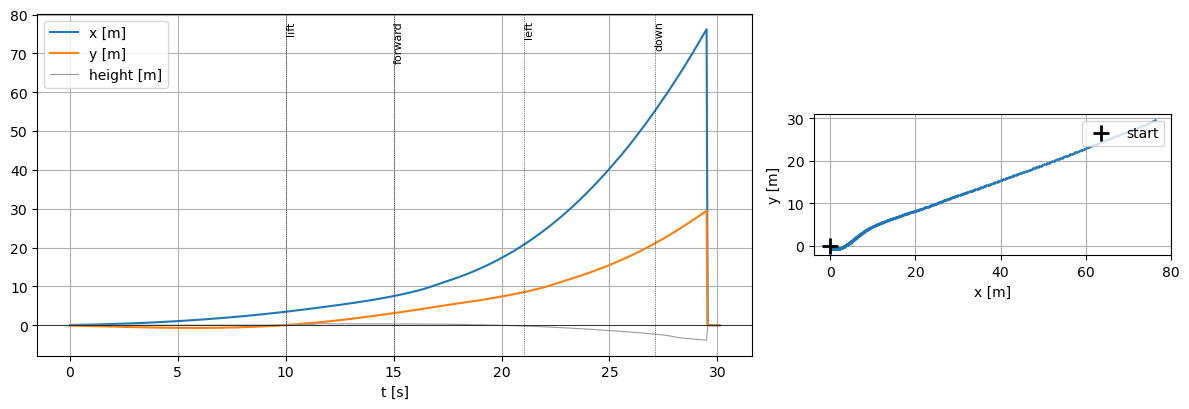

In [4]:
t = (d['t_ms'] - d['t_ms'][0]) / 1000.0
fig, ax = plt.subplots(2, 2, figsize=(12, 7.5), gridspec_kw={'width_ratios': [2, 1]})

# the estimate
ax[0, 0].plot(t, d['x'], label='x [m]')
ax[0, 0].plot(t, d['y'], label='y [m]')
ax[0, 0].plot(t, d['z'], color='0.6', lw=0.8, label='height [m]')
for name in ('lift', 'forward', 'left', 'down'):
    m = d['phase'] == name
    if m.any():
        for a in (ax[0, 0], ax[1, 0]):
            a.axvline(t[m][0], color='k', lw=0.5, ls=':')
        ax[0, 0].text(t[m][0], 0.98, name, fontsize=8, rotation=90, va='top', transform=ax[0, 0].get_xaxis_transform())
ax[0, 0].axhline(0, color='k', lw=0.5)
ax[0, 0].set_ylabel('position estimate')
ax[0, 0].legend(loc='upper left')
ax[0, 0].grid()

# what the flow deck itself reported
ax[1, 0].plot(t, d['flow_dx'], label='flow dx [counts]')
ax[1, 0].plot(t, d['flow_dy'], label='flow dy [counts]')
ax[1, 0].plot(t, d['squal'], color='0.4', lw=0.8, label='surface quality')
ax[1, 0].axhline(0, color='k', lw=0.5)
ax[1, 0].set_xlabel('t [s]')
ax[1, 0].set_ylabel('flow deck')
ax[1, 0].legend(loc='upper left')
ax[1, 0].grid()

# the path in the plane
ax[0, 1].plot(d['x'], d['y'], '.', ms=2)
ax[0, 1].plot(0, 0, 'k+', ms=12, mew=2, label='start')
ax[0, 1].set_xlabel('x [m]')
ax[0, 1].set_ylabel('y [m]')
ax[0, 1].set_aspect('equal')
ax[0, 1].legend(loc='upper right')
ax[0, 1].grid()

# the height: estimate against the range sensor
ax[1, 1].plot(t, d['zrange_m'], label='range sensor [m]')
ax[1, 1].plot(t, d['z'], label='estimate z [m]')
ax[1, 1].set_xlabel('t [s]')
ax[1, 1].legend(loc='upper left')
ax[1, 1].grid()
plt.tight_layout()

limits = crazyflie.gain_limits(ident)
print(f"noise limits for the gains (command jitter below {limits['jitter_mps']} m/s): "
      f"|Kp| < {limits['Kp_max']:.1f} 1/s, |Kd| < {limits['Kd_max']:.1f}")


## What the numbers mean

* **Flow sensor.** The estimate is only as good as the sensor behind it. The counts during the moves and the surface quality say whether the flow sensor saw the table at all. Zero counts during a move means a blind sensor: a blocked window, a plain surface or a dead deck. Then nothing below means anything, and part 3 refuses to fly.
* **Axes.** The forward move must increase `x` and the left move must increase `y`: then `+x` is forward and `+y` is left, as the controller in part 3 assumes when it uses negative gains. With a reversed axis the same gains would push the drone away from its setpoint; the flight function warns when the file says so. How far the estimate moved is not used: a hand does not move 30 cm to the centimetre, and the controller does not need the number.
* **Noise.** The standard deviations of `x` and `vx` while the drone lay still are the floor of the measurement. The position loop multiplies them by its gains: `|Kp|` times the position noise plus `|Kd|` times the velocity noise is the jitter of the velocity command. Keeping that below 0.05 m/s gives the two limits printed above. These are upper bounds, not recommendations; part 3 chooses the gains from the response time of the drone and checks them against these limits.
* **Drift.** The change of the estimate during the still phase, with nothing moving. In flight the drone follows a drift of the estimate, because it holds the estimated position, not the true one.

The file `data/drone_id.csv` holds these numbers, one per line with a comment. Part 3 reads it before every flight. The samples are kept as `data/sensor_id_<drone label>_<time>.csv`; no notebook needs that file, it is there to compare runs and drones.

Next: `drone_03_position_loop`, where the drone flies for the first time, under its own controllers, to measure how fast it follows a velocity command.
